# Sleep Staging — 05: Gradient Boosting Models

**Objetivo:** comparar XGBoost, LightGBM y CatBoost sobre las mismas features y con el mismo split por sujeto usado en la notebook 05.

**Referencia baseline (notebook 04):** SGD con todas las features, holdout Macro-F1 ≈ 0.730.

Los modelos se ejecutan en CPU, con un solo thread y con guardado por fold para poder reanudar el proceso.


---
## 0. Setup


In [1]:
import os
for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[variable] = "1"

from pathlib import Path
import gc, json, time, warnings
import joblib
import numpy as np
import pandas as pd
import psutil

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score,
)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

DATA_DIR = Path("../data/processed")
FIGURES_DIR = Path("../reports/figures")
MODELS_DIR = Path("../models")
RESULTS_DIR = Path("../reports/results")

FEATURES_PATH = DATA_DIR / "features_full.parquet"
BASELINE_CV_PATH = RESULTS_DIR / "baseline_feature_reduction_cv.csv"
BASELINE_HOLDOUT_PATH = RESULTS_DIR / "baseline_holdout_metrics.json"

FOLD_RESULTS_PATH = RESULTS_DIR / "boosting_fold_results.csv"
CV_RESULTS_PATH = RESULTS_DIR / "boosting_cv_results.csv"
HOLDOUT_PATH = RESULTS_DIR / "boosting_holdout_metrics.json"
PREDICTIONS_PATH = RESULTS_DIR / "boosting_holdout_predictions.parquet"
MODEL_PATH = MODELS_DIR / "boosting_best_model.joblib"

for d in (FIGURES_DIR, MODELS_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 3
N_CLASSES = 5
SELECTION_TOLERANCE = 0.005

STAGE_MAP = {0: "W", 1: "N1", 2: "N2", 3: "N3", 4: "REM"}
STAGE_ORDER = list(STAGE_MAP)
STAGE_NAMES = [STAGE_MAP[i] for i in STAGE_ORDER]

print("Setup completado.")


Setup completado.


---
## 1. Carga y validación del dataset


In [2]:
if not FEATURES_PATH.exists():
    raise FileNotFoundError(f"No se encontró: {FEATURES_PATH.resolve()}")

features_df = pd.read_parquet(FEATURES_PATH)
METADATA_COLS = ["epoch_global", "epoch_in_subject", "label", "subject"]
FEATURE_COLS = [c for c in features_df.columns if c not in METADATA_COLS]

X = features_df[FEATURE_COLS].astype(np.float32)
y = features_df["label"].astype(np.int8)
groups = features_df["subject"].astype(str)

assert len(X) == len(y) == len(groups)
assert set(y.unique()).issubset(STAGE_MAP)

print(f"Dataset:  {features_df.shape}")
print(f"Features: {len(FEATURE_COLS)}")
print(f"Sujetos:  {groups.nunique()}")


Dataset:  (127904, 197)
Features: 193
Sujetos:  151


---
## 2. Mismo holdout por sujeto que en la notebook 04


In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, groups_test = groups.iloc[train_idx].copy(), groups.iloc[test_idx].copy()

train_subjects = set(groups_train.unique())
test_subjects = set(groups_test.unique())
assert train_subjects.isdisjoint(test_subjects)

del X
gc.collect()

print(f"Train epochs:  {len(X_train)}")
print(f"Test epochs:   {len(X_test)}")
print(f"Train subjects:{len(train_subjects)}")
print(f"Test subjects: {len(test_subjects)}")
print(f"RAM kernel:    {psutil.Process(os.getpid()).memory_info().rss / 1024**3:.2f} GB")


Train epochs:  103338
Test epochs:   24566
Train subjects:120
Test subjects: 31
RAM kernel:    0.43 GB


---
## 3. Resultados de referencia del baseline


In [4]:
baseline_cv = pd.read_csv(BASELINE_CV_PATH) if BASELINE_CV_PATH.exists() else None
baseline_holdout = None

if baseline_cv is not None:
    display(baseline_cv.sort_values("f1_macro_mean", ascending=False).round(4))

if BASELINE_HOLDOUT_PATH.exists():
    with open(BASELINE_HOLDOUT_PATH, "r", encoding="utf-8") as f:
        baseline_holdout = json.load(f)
    display(pd.Series(baseline_holdout).to_frame("value"))


,experiment,fit_time_mean,fit_time_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean,f1_macro_std
0,Random Forest | All features,206.9649,18.3705,0.7527,0.0108,0.7124,0.0092,0.7098,0.0129
1,SGD | All features,33.2733,1.3327,0.7520,0.0110,0.7187,0.0100,0.7092,0.0129
2,Random Forest | ANOVA top 50,103.5692,3.9538,0.7345,0.0119,0.6934,0.0089,0.6887,0.0124
3,SGD | ANOVA top 50,11.0363,0.1139,0.7232,0.0117,0.6778,0.0077,0.6687,0.0078
4,SGD | Mutual information top 50,123.9546,2.3351,0.7011,0.0156,0.6585,0.0166,0.6462,0.0212
5,Dummy | All features,0.0732,0.0057,0.3737,0.0253,0.2000,0.0000,0.1087,0.0054


,value
experiment,SGD | All features
accuracy,0.76614
balanced_accuracy,0.739709
f1_macro,0.72986
n_train_epochs,103338
n_test_epochs,24566
n_train_subjects,120
n_test_subjects,31


---
## 4. Configuración de modelos


In [5]:
models = {
    "XGBoost": XGBClassifier(
        objective="multi:softprob", num_class=N_CLASSES,
        n_estimators=250, learning_rate=0.05, max_depth=6,
        min_child_weight=2, subsample=0.85, colsample_bytree=0.85,
        reg_alpha=0.05, reg_lambda=1.0,
        tree_method="hist", device="cpu", eval_metric="mlogloss",
        n_jobs=1, random_state=RANDOM_STATE,
    ),
    "LightGBM": LGBMClassifier(
        objective="multiclass", num_class=N_CLASSES,
        n_estimators=250, learning_rate=0.05, num_leaves=31,
        min_child_samples=30, subsample=0.85, colsample_bytree=0.85,
        reg_alpha=0.05, reg_lambda=1.0, class_weight="balanced",
        n_jobs=1, random_state=RANDOM_STATE, verbosity=-1,
    ),
    "CatBoost": CatBoostClassifier(
        loss_function="MultiClass", iterations=250,
        learning_rate=0.05, depth=7, l2_leaf_reg=3.0,
        auto_class_weights="Balanced", random_seed=RANDOM_STATE,
        thread_count=1, verbose=False, allow_writing_files=False,
        task_type="CPU",
    ),
}

for name in models:
    print("-", name)


- XGBoost
- LightGBM
- CatBoost


---
## 5. Funciones de evaluación


In [6]:
def evaluate_fold(model, X_fit, y_fit, X_valid, y_valid):
    start = time.perf_counter()
    model.fit(X_fit, y_fit)
    pred = np.asarray(model.predict(X_valid)).reshape(-1)
    return {
        "accuracy": accuracy_score(y_valid, pred),
        "balanced_accuracy": balanced_accuracy_score(y_valid, pred),
        "f1_macro": f1_score(y_valid, pred, average="macro"),
        "fit_time": time.perf_counter() - start,
    }


def summarize(results):
    rows=[]
    for name, g in results.groupby("model"):
        row={"model":name}
        for metric in ["accuracy", "balanced_accuracy", "f1_macro", "fit_time"]:
            row[f"{metric}_mean"] = g[metric].mean()
            row[f"{metric}_std"] = g[metric].std(ddof=0)
        rows.append(row)
    return pd.DataFrame(rows).sort_values("f1_macro_mean", ascending=False).reset_index(drop=True)


---
## 6. Cross-validation recuperable


In [7]:
if FOLD_RESULTS_PATH.exists():
    fold_results = pd.read_csv(FOLD_RESULTS_PATH)
    completed = set(zip(fold_results["model"], fold_results["fold"]))
    print(f"Folds recuperados: {len(completed)}")
else:
    fold_results = pd.DataFrame()
    completed = set()

cv = GroupKFold(n_splits=N_SPLITS)

for model_name, base_model in models.items():
    print(f"\n{'='*60}\n{model_name}\n{'='*60}")

    for fold, (fit_idx, valid_idx) in enumerate(
        cv.split(X_train, y_train, groups_train), start=1
    ):
        if (model_name, fold) in completed:
            print(f"Fold {fold}: ya evaluado")
            continue

        print(
            f"Fold {fold}/{N_SPLITS} | "
            f"RAM: {psutil.Process(os.getpid()).memory_info().rss / 1024**3:.2f} GB"
        )

        model = clone(base_model)
        result = evaluate_fold(
            model,
            X_train.iloc[fit_idx], y_train.iloc[fit_idx],
            X_train.iloc[valid_idx], y_train.iloc[valid_idx],
        )
        result.update({
            "model": model_name,
            "fold": fold,
            "n_train": len(fit_idx),
            "n_valid": len(valid_idx),
        })

        fold_results = pd.concat([fold_results, pd.DataFrame([result])], ignore_index=True)
        fold_results.to_csv(FOLD_RESULTS_PATH, index=False)

        print(
            f"Macro-F1: {result['f1_macro']:.4f} | "
            f"Balanced acc: {result['balanced_accuracy']:.4f} | "
            f"Tiempo: {result['fit_time']:.1f}s"
        )

        del model
        gc.collect()

cv_results = summarize(fold_results)
cv_results.to_csv(CV_RESULTS_PATH, index=False)
display(cv_results.round(4))



XGBoost
Fold 1/3 | RAM: 0.44 GB
Macro-F1: 0.7162 | Balanced acc: 0.7162 | Tiempo: 240.6s
Fold 2/3 | RAM: 0.54 GB
Macro-F1: 0.7322 | Balanced acc: 0.7310 | Tiempo: 243.4s
Fold 3/3 | RAM: 0.54 GB
Macro-F1: 0.7290 | Balanced acc: 0.7203 | Tiempo: 243.6s

LightGBM
Fold 1/3 | RAM: 0.54 GB
Macro-F1: 0.7242 | Balanced acc: 0.7354 | Tiempo: 150.7s
Fold 2/3 | RAM: 0.54 GB
Macro-F1: 0.7355 | Balanced acc: 0.7436 | Tiempo: 154.5s
Fold 3/3 | RAM: 0.54 GB
Macro-F1: 0.7324 | Balanced acc: 0.7419 | Tiempo: 151.6s

CatBoost
Fold 1/3 | RAM: 0.54 GB
Macro-F1: 0.7067 | Balanced acc: 0.7231 | Tiempo: 1025.4s
Fold 2/3 | RAM: 0.32 GB
Macro-F1: 0.7229 | Balanced acc: 0.7352 | Tiempo: 690.4s
Fold 3/3 | RAM: 0.32 GB
Macro-F1: 0.7229 | Balanced acc: 0.7355 | Tiempo: 911.9s


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean,f1_macro_std,fit_time_mean,fit_time_std
0,LightGBM,0.7563,0.0056,0.7403,0.0035,0.7307,0.0047,152.2407,1.6321
1,XGBoost,0.7719,0.0053,0.7225,0.0063,0.7258,0.0069,242.5491,1.3923
2,CatBoost,0.7416,0.0077,0.7313,0.0057,0.7175,0.0076,875.9248,139.1077


---
## 7. Comparación contra el baseline


In [8]:
comparison_rows=[]

if baseline_cv is not None:
    ref = baseline_cv[baseline_cv["experiment"] == "SGD | All features"]
    if not ref.empty:
        r=ref.iloc[0]
        comparison_rows.append({
            "model":"SGD baseline",
            "accuracy_mean":r["accuracy_mean"],
            "balanced_accuracy_mean":r["balanced_accuracy_mean"],
            "f1_macro_mean":r["f1_macro_mean"],
            "fit_time_mean":r["fit_time_mean"],
        })

for _, r in cv_results.iterrows():
    comparison_rows.append({
        "model":r["model"],
        "accuracy_mean":r["accuracy_mean"],
        "balanced_accuracy_mean":r["balanced_accuracy_mean"],
        "f1_macro_mean":r["f1_macro_mean"],
        "fit_time_mean":r["fit_time_mean"],
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values("f1_macro_mean", ascending=False)
display(comparison_df.round(4))


,model,accuracy_mean,balanced_accuracy_mean,f1_macro_mean,fit_time_mean
1,LightGBM,0.7563,0.7403,0.7307,152.2407
2,XGBoost,0.7719,0.7225,0.7258,242.5491
3,CatBoost,0.7416,0.7313,0.7175,875.9248
0,SGD baseline,0.7520,0.7187,0.7092,33.2733


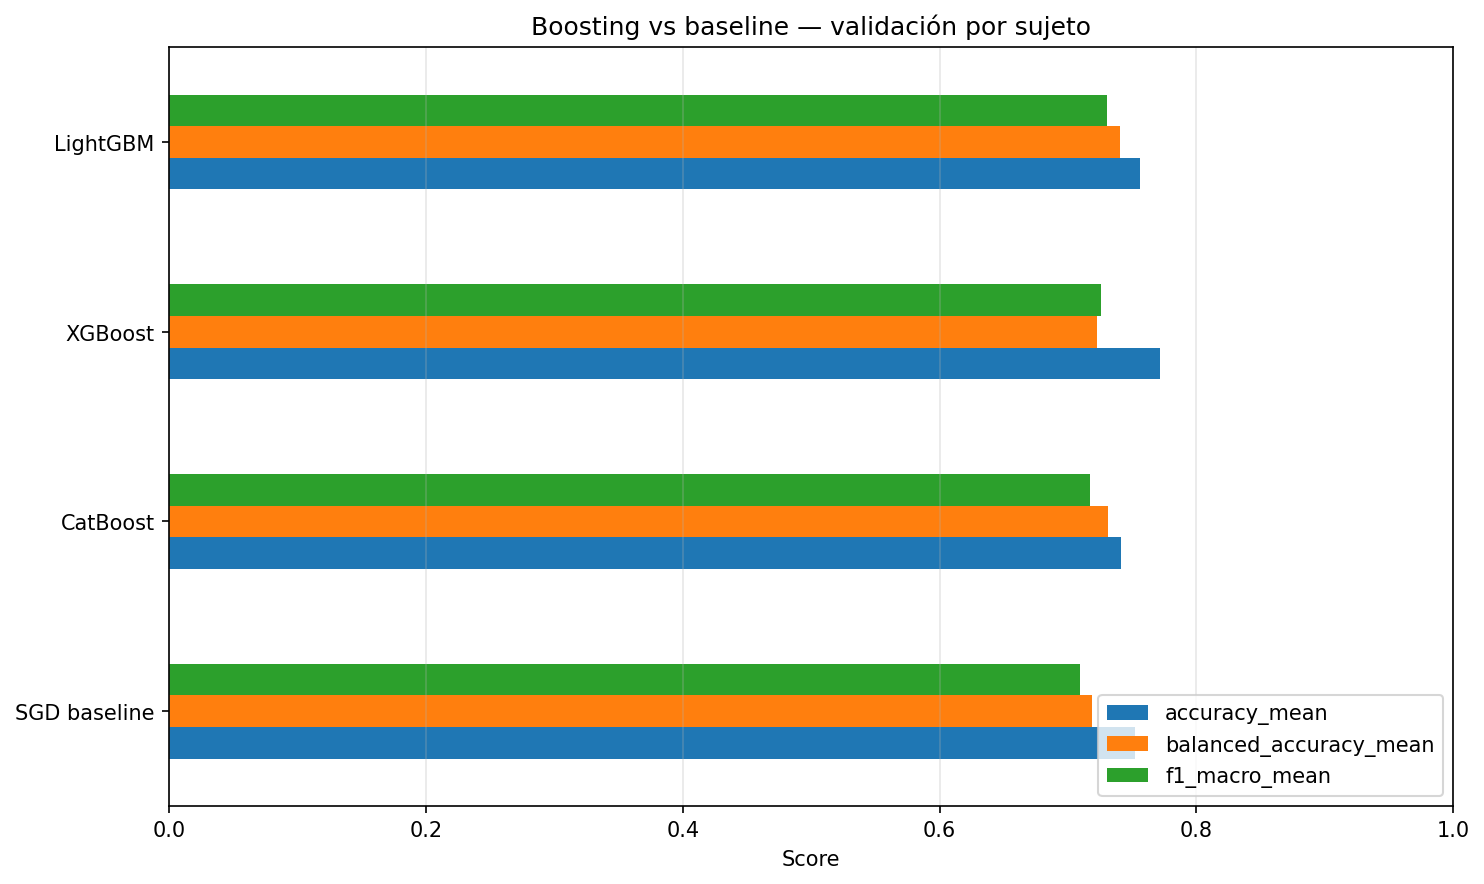

In [9]:
PLOT_PATH = FIGURES_DIR / "boosting_vs_baseline_cv.png"
plot_df = comparison_df.set_index("model")[[
    "accuracy_mean", "balanced_accuracy_mean", "f1_macro_mean"
]].sort_values("f1_macro_mean")

fig, ax = plt.subplots(figsize=(10, 6))
plot_df.plot(kind="barh", ax=ax)
ax.set_title("Boosting vs baseline — validación por sujeto")
ax.set_xlabel("Score")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_PATH, dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(PLOT_PATH), width=950))


---
## 8. Selección y entrenamiento final


In [10]:
best_f1 = cv_results["f1_macro_mean"].max()
competitive = cv_results[
    cv_results["f1_macro_mean"] >= best_f1 - SELECTION_TOLERANCE
]

preferred_order = ["LightGBM", "XGBoost", "CatBoost"]
best_model_name = next(
    name for name in preferred_order
    if name in competitive["model"].values
)

best_model = clone(models[best_model_name])
print("Modelo seleccionado:", best_model_name)
display(competitive.round(4))

best_model.fit(X_train, y_train)
y_pred = np.asarray(best_model.predict(X_test)).reshape(-1)

holdout_metrics = {
    "model": best_model_name,
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, y_pred)),
    "f1_macro": float(f1_score(y_test, y_pred, average="macro")),
    "n_train_epochs": int(len(X_train)),
    "n_test_epochs": int(len(X_test)),
    "n_train_subjects": int(len(train_subjects)),
    "n_test_subjects": int(len(test_subjects)),
}

display(pd.Series(holdout_metrics).to_frame("value"))
print(classification_report(
    y_test, y_pred, labels=STAGE_ORDER,
    target_names=STAGE_NAMES, digits=4, zero_division=0,
))


Modelo seleccionado: LightGBM


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean,f1_macro_std,fit_time_mean,fit_time_std
0,LightGBM,0.7563,0.0056,0.7403,0.0035,0.7307,0.0047,152.2407,1.6321
1,XGBoost,0.7719,0.0053,0.7225,0.0063,0.7258,0.0069,242.5491,1.3923


,value
model,LightGBM
accuracy,0.755597
balanced_accuracy,0.745776
f1_macro,0.737834
n_train_epochs,103338
n_test_epochs,24566
n_train_subjects,120
n_test_subjects,31


              precision    recall  f1-score   support

           W     0.8365    0.7727    0.8033      3409
          N1     0.4189    0.5422    0.4727      2831
          N2     0.8265    0.7380    0.7797      9617
          N3     0.7894    0.8342    0.8112      4663
         REM     0.8037    0.8418    0.8223      4046

    accuracy                         0.7556     24566
   macro avg     0.7350    0.7458    0.7378     24566
weighted avg     0.7701    0.7556    0.7606     24566



### 8.1 Matriz de confusión


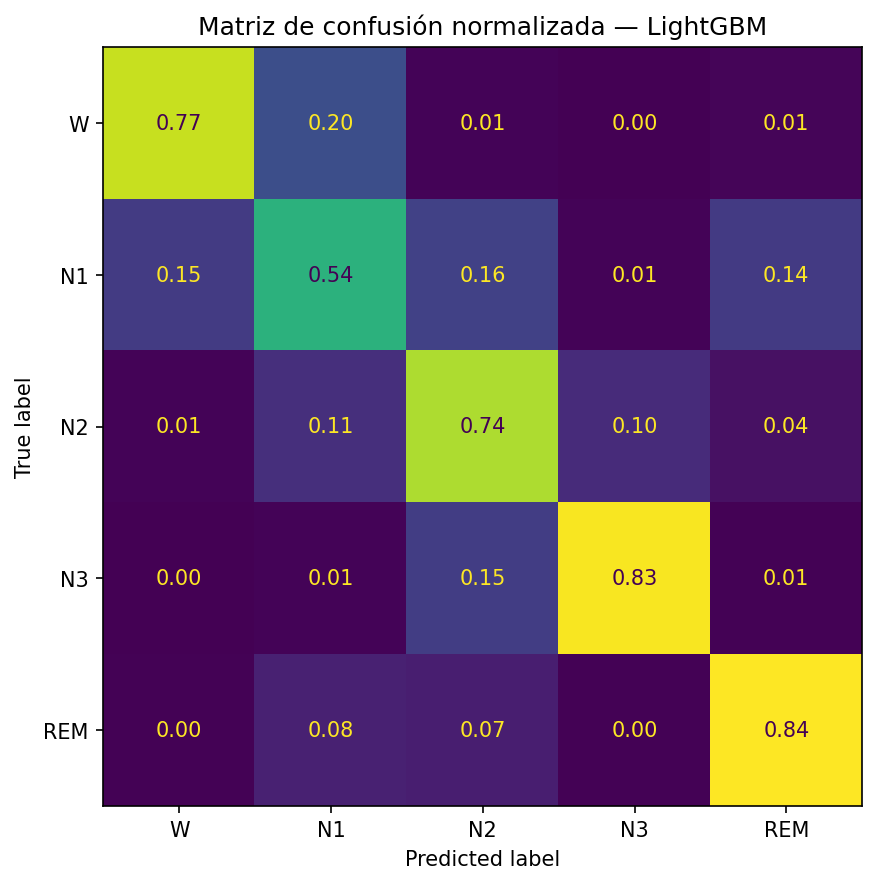

In [11]:
CM_PATH = FIGURES_DIR / "boosting_holdout_confusion_matrix.png"
cm = confusion_matrix(y_test, y_pred, labels=STAGE_ORDER, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=STAGE_NAMES).plot(
    ax=ax, values_format=".2f", colorbar=False
)
ax.set_title(f"Matriz de confusión normalizada — {best_model_name}")
fig.tight_layout()
fig.savefig(CM_PATH, dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(CM_PATH), width=700))


---
## 9. Importancia de features


In [12]:
importance_df = None
if hasattr(best_model, "feature_importances_"):
    importance_df = pd.DataFrame({
        "feature": FEATURE_COLS,
        "importance": np.asarray(best_model.feature_importances_, dtype=float),
    }).sort_values("importance", ascending=False).reset_index(drop=True)
    display(importance_df.head(20))


,feature,importance
0,EMG chin__perm_entropy,751.0
1,EEG O2-M1__ratio_theta_alpha,694.0
2,EEG C3-M2__ratio_sigma_beta,669.0
3,EMG chin__zcr,577.0
4,EEG O2-M1__perm_entropy,533.0
5,EMG chin__power_20_35,501.0
6,EOG E2-M2__beta_abs,489.0
7,EEG C3-M2__delta_abs,483.0
8,EOG E2-M2__perm_entropy,480.0
9,EOG E1-M2__alpha_abs,469.0


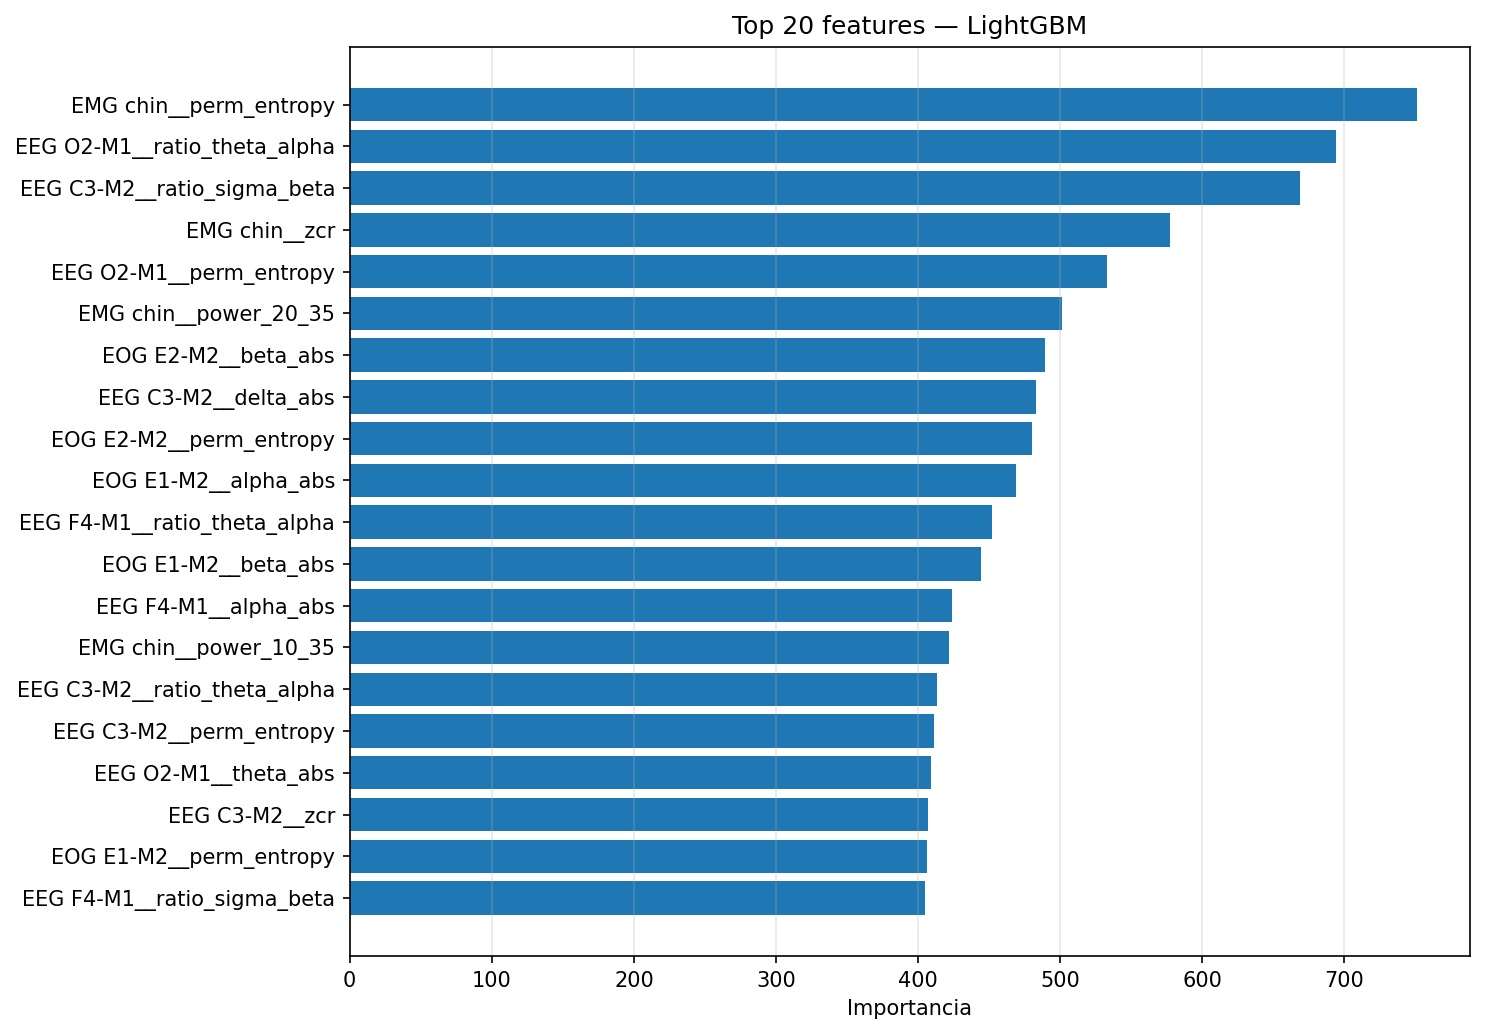

In [13]:
if importance_df is not None:
    IMP_PATH = FIGURES_DIR / "boosting_feature_importance.png"
    top = importance_df.head(20).sort_values("importance")
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(top["feature"], top["importance"])
    ax.set_title(f"Top 20 features — {best_model_name}")
    ax.set_xlabel("Importancia")
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    fig.savefig(IMP_PATH, dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(IMP_PATH), width=950))


---
## 10. Guardado de artefactos


In [14]:
joblib.dump({
    "model": best_model,
    "feature_names": FEATURE_COLS,
    "stage_map": STAGE_MAP,
    "model_name": best_model_name,
}, MODEL_PATH)

predictions_df = features_df.iloc[test_idx][METADATA_COLS].copy()
predictions_df["y_true"] = y_test.to_numpy()
predictions_df["y_pred"] = y_pred.astype(np.int8)
predictions_df.to_parquet(PREDICTIONS_PATH, index=False)

with open(HOLDOUT_PATH, "w", encoding="utf-8") as f:
    json.dump(holdout_metrics, f, indent=2, ensure_ascii=False)

print("Modelo:", MODEL_PATH.resolve())
print("Predicciones:", PREDICTIONS_PATH.resolve())
print("Métricas:", HOLDOUT_PATH.resolve())


Modelo: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\models\boosting_best_model.joblib
Predicciones: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\boosting_holdout_predictions.parquet
Métricas: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\boosting_holdout_metrics.json


---
## 11. Checklist final


In [15]:
checks = {
    "Sin solapamiento de sujetos": train_subjects.isdisjoint(test_subjects),
    "Resultados por fold guardados": FOLD_RESULTS_PATH.exists(),
    "Resumen de CV guardado": CV_RESULTS_PATH.exists(),
    "Modelo guardado": MODEL_PATH.exists(),
    "Predicciones guardadas": PREDICTIONS_PATH.exists(),
    "Métricas guardadas": HOLDOUT_PATH.exists(),
    "Predicciones alineadas": len(y_pred) == len(y_test),
}

for label, passed in checks.items():
    print(f"{'✅' if passed else '❌'}  {label}")

print(f"\nModelo: {best_model_name}")
print(f"Holdout accuracy: {holdout_metrics['accuracy']:.4f}")
print(f"Holdout balanced accuracy: {holdout_metrics['balanced_accuracy']:.4f}")
print(f"Holdout Macro-F1: {holdout_metrics['f1_macro']:.4f}")


✅  Sin solapamiento de sujetos
✅  Resultados por fold guardados
✅  Resumen de CV guardado
✅  Modelo guardado
✅  Predicciones guardadas
✅  Métricas guardadas
✅  Predicciones alineadas

Modelo: LightGBM
Holdout accuracy: 0.7556
Holdout balanced accuracy: 0.7458
Holdout Macro-F1: 0.7378
